# Serie A 2025-26: young midfielders, scouting profiles

**Question.** Which Serie A midfielders born in 2002 or later (under 24 now) stand out, and in what way? The output is a short list per playing profile and a card for each selected player: what the numbers say, who he resembles, and what to check on video.

**Design, fixed before looking at results**
- Population: Serie A midfielders (FBref position starts with `MF`) with at least 900 minutes in 2025-26.
- Eight per-90 metrics, converted to percentiles within that population.
- Four profiles, two metrics each, score = mean percentile: **Creator** (xA, key passes), **Builder** (xGBuildup, xGChain), **Ball-winner** (tackles won, interceptions), **Goal threat** (npxG, shots).
- Shortlist: top six per profile among players born 2002 or later. Cards: top two per profile with at least 1,400 minutes, no player twice.
- **Price and club are not used in selection.** No market data is included in this version.

**Data (not redistributed here)**
- Understat (via the `understatapi` package): xG, xA, shots, key passes, xGChain, xGBuildup. Season "2025" = 2025-26.
- Kaggle `hubertsidorowicz/football-players-stats-2025-2026` (FBref-based): age, birth year, position, minutes, tackles won, interceptions. This file has no xG, passing or progression columns even though its Kaggle description lists them, so the two sources are combined.
- Check each source's terms before reusing the data.

**Written on 22 October 2026. No 2026-27 data are used.**

In [1]:
!pip -q install understatapi

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 537.7/537.7 kB 5.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.4/159.4 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.1/153.1 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.7/64.7 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.1/138.1 kB 11.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.5 which is incompatible.
httpx2 2.13.1 requires idna>=3.1

In [2]:
import pandas as pd, numpy as np, unicodedata, difflib, os
import matplotlib.pyplot as plt
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

FOLDER = "/content/drive/MyDrive/football_portfolio"   # change if needed

def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.lower() if ch.isalpha())

LEAGUES = {"EPL": "eng Premier League", "La_Liga": "es La Liga",
           "Bundesliga": "de Bundesliga", "Serie_A": "it Serie A", "Ligue_1": "fr Ligue 1"}
NUMC = ["games", "time", "goals", "xG", "assists", "xA", "shots", "key_passes",
        "npg", "npxG", "xGChain", "xGBuildup"]

def fetch_understat(season, leagues, cache):
    # downloads once, then reads the cached csv
    if os.path.exists(cache):
        return pd.read_csv(cache)
    from understatapi import UnderstatClient
    frames = []
    with UnderstatClient() as u:
        for lg, comp in leagues.items():
            df = pd.DataFrame(u.league(league=lg).get_player_data(season=season))
            df["Comp"] = comp
            frames.append(df)
    out = pd.concat(frames, ignore_index=True)
    out[NUMC] = out[NUMC].apply(pd.to_numeric, errors="coerce")
    out.to_csv(cache, index=False)
    return out

us = fetch_understat("2025", LEAGUES, f"{FOLDER}/understat_2025_players.csv")
fb = pd.read_csv(f"{FOLDER}/players_data-2025_2026.csv")
print("Understat rows:", len(us), "| FBref-based rows:", len(fb))
print(fb.columns.tolist()[:25], "... (no xG / passing / progression columns)")

Mounted at /content/drive
Understat rows: 2775 | FBref-based rows: 2839
['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'G+A-PK', 'Rk_stats_keeper', 'Nation_stats_keeper', 'Pos_stats_keeper', 'Comp_stats_keeper'] ... (no xG / passing / progression columns)


## 1. Combining the two sources

Players are matched by name inside the same league (exact, then fuzzy, then name-contained-in-name with similar minutes). Players who changed club mid-season have their FBref rows summed. A short manual alias list covers names written differently in the two sources (`Nico Paz` is `Nicolás Paz` in FBref). Matches whose minutes differ by more than 10% are dropped from the analysis.

In [3]:
fbx = fb[["Player", "Squad", "Comp", "Pos", "Age", "Born", "Min", "TklW", "Int", "Crs", "Fld", "Fls"]].copy()
fbx["key"] = fbx.Player.map(norm)
fbx = fbx.sort_values("Min", ascending=False)
agg = fbx.groupby(["Comp", "key"]).agg(
    Player=("Player", "first"), Squad=("Squad", lambda s: ",".join(s)), Pos=("Pos", "first"),
    Age=("Age", "first"), Born=("Born", "first"), Min=("Min", "sum"),
    TklW=("TklW", "sum"), Int=("Int", "sum"), Crs=("Crs", "sum"),
    Fld=("Fld", "sum"), Fls=("Fls", "sum")).reset_index()
by_comp = {c: g.reset_index(drop=True) for c, g in agg.groupby("Comp")}

ALIAS = {"nicopaz": "nicolaspaz", "kouadiokone": "manukone", "tasosdouvikas": "anastasiosdouvikas"}

rows, how = [], []
for _, r in us.iterrows():
    g = by_comp[r.Comp]
    k = ALIAS.get(norm(r.player_name), norm(r.player_name))
    hit, method = None, "none"
    e = g.index[g.key == k]
    if len(e):
        hit, method = e[0], "exact"
    if hit is None:
        mm = difflib.get_close_matches(k, list(g.key), n=1, cutoff=0.88)
        if mm:
            hit, method = g.index[g.key == mm[0]][0], "fuzzy"
    if hit is None and len(k) >= 5:
        sub = g[g.key.map(lambda x: (k in x or x in k) and min(len(k), len(x)) >= 5)]
        sub = sub[(sub.Min - r.time).abs() <= 0.25 * max(r.time, 1)]
        if len(sub):
            hit, method = (sub.Min - r.time).abs().idxmin(), "substring"
    rows.append(None if hit is None else (r.Comp, hit)); how.append(method)

recs = [by_comp[k[0]].loc[k[1]].to_dict() if k else {} for k in rows]
m = pd.concat([us.reset_index(drop=True), pd.DataFrame(recs).add_prefix("fb_")], axis=1)
m["match"] = how
m["min_diff"] = (m.fb_Min - m.time).abs() / m.time.clip(lower=1)

big = m[m.time >= 900]
print("match method:", m.match.value_counts().to_dict())
print("matched share, players >=900 min: all leagues %.3f | Serie A %.3f" % (
    (big.match != "none").mean(), (big[big.Comp == "it Serie A"].match != "none").mean()))
bad = m[(m.Comp == "it Serie A") & (m.time >= 900) & ((m.match == "none") | (m.min_diff > 0.10))]
print("Serie A, >=900 min, unmatched or minutes differ >10%%: %d" % len(bad))
print(bad[["player_name", "team_title", "time", "match", "fb_Player", "fb_Min"]].to_string(index=False))

match method: {'exact': 2484, 'none': 138, 'substring': 77, 'fuzzy': 76}
matched share, players >=900 min: all leagues 0.960 | Serie A 0.979
Serie A, >=900 min, unmatched or minutes differ >10%: 7
               player_name team_title  time match fb_Player  fb_Min
  Jonathan Christian David   Juventus  1784  none       NaN     NaN
              Leo Østigard      Genoa  2631  none       NaN     NaN
              Franck Zambo     Napoli  1253  none       NaN     NaN
              Yann Bisseck      Inter  1924  none       NaN     NaN
               Evan Ndicka       Roma  2686  none       NaN     NaN
Thomas Thiesson Kristensen    Udinese  2482  none       NaN     NaN
        Oliver Provstgaard      Lazio  1515  none       NaN     NaN


## 2. Metrics and percentiles

All metrics are per 90 minutes. Percentiles are computed among Serie A midfielders with at least 900 minutes, so a profile score of 90 means "better than about 90% of Serie A midfielders on these two metrics", at any age.

In [4]:
sa = m[(m.Comp == "it Serie A") & (m.time >= 900) & (m.match != "none")
       & (m.min_diff <= 0.10) & m.fb_Pos.fillna("").str.startswith("MF")].copy()
n90 = sa.time / 90
sa["npxG90"] = sa.npxG / n90
sa["shots90"] = sa.shots / n90
sa["xA90"] = sa.xA / n90
sa["KP90"] = sa.key_passes / n90
sa["xGChain90"] = sa.xGChain / n90
sa["xGBuildup90"] = sa.xGBuildup / n90
sa["TklW90"] = sa.fb_TklW / n90
sa["Int90"] = sa.fb_Int / n90
sa["Born"] = sa.fb_Born
METRICS = ["npxG90", "shots90", "xA90", "KP90", "xGChain90", "xGBuildup90", "TklW90", "Int90"]
for c in METRICS:
    sa["p_" + c] = sa[c].rank(pct=True) * 100
sa = sa.reset_index(drop=True)
print("Serie A midfielders with >=900 min:", len(sa),
      "| born 2002 or later:", int((sa.Born >= 2002).sum()))

Serie A midfielders with >=900 min: 153 | born 2002 or later: 44


## 3. How reliable are the metrics?

For Serie A players with at least 900 minutes in both 2024-25 and 2025-26, rank correlation of the per-90 metric between the two seasons. A low number means the metric depends on team, role or luck and deserves less weight. (Tackles won and interceptions are not tested because the 2024-25 FBref file is not used here.)

In [5]:
old = fetch_understat("2024", {"Serie_A": "it Serie A"}, f"{FOLDER}/understat_2024_serie_a.csv")
new = us[us.Comp == "it Serie A"].copy()
old["id"] = old["id"].astype(int); new["id"] = new["id"].astype(int)
j = old.merge(new, on="id", suffixes=("_24", "_25"))
j = j[(j.time_24 >= 900) & (j.time_25 >= 900)]
print("Serie A players with 900+ min in both seasons:", len(j))
rel = []
for name, col in [("npxG per 90", "npxG"), ("shots per 90", "shots"), ("xA per 90", "xA"),
                  ("key passes per 90", "key_passes"), ("xGChain per 90", "xGChain"),
                  ("xGBuildup per 90", "xGBuildup")]:
    a = j[col + "_24"] / (j.time_24 / 90)
    b = j[col + "_25"] / (j.time_25 / 90)
    rel.append((name, round(a.corr(b, method="spearman"), 2)))
print(pd.DataFrame(rel, columns=["metric", "year-to-year rank correlation"]).to_string(index=False))

Serie A players with 900+ min in both seasons: 208
           metric  year-to-year rank correlation
      npxG per 90                           0.82
     shots per 90                           0.88
        xA per 90                           0.74
key passes per 90                           0.86
   xGChain per 90                           0.77
 xGBuildup per 90                           0.67


## 4. Shortlists by profile (born 2002 or later)

In [6]:
PROFILES = {
    "Creator (xA, key passes)":        ["xA90", "KP90"],
    "Builder (xGBuildup, xGChain)":    ["xGBuildup90", "xGChain90"],
    "Ball-winner (tackles won, int.)": ["TklW90", "Int90"],
    "Goal threat (npxG, shots)":       ["npxG90", "shots90"],
}
show = ["player_name", "team_title", "Born", "time"] + METRICS
for name, ms in PROFILES.items():
    sa["score_" + name] = sa[["p_" + x for x in ms]].mean(axis=1)
    top = sa[sa.Born >= 2002].sort_values("score_" + name, ascending=False).head(6)
    print("\n=== " + name + " ===")
    print(top[show + ["score_" + name]].round(2).to_string(index=False))


=== Creator (xA, key passes) ===
    player_name team_title   Born  time  npxG90  shots90  xA90  KP90  xGChain90  xGBuildup90  TklW90  Int90  score_Creator (xA, key passes)
Martin Baturina       Como 2003.0  1579    0.11     1.60  0.38  3.48       0.68         0.40    0.80   0.28                           98.69
   Kenan Yildiz   Juventus 2005.0  2877    0.22     3.03  0.34  2.38       0.71         0.32    0.44   0.22                           95.42
Jesús Rodriguez       Como 2005.0  1728    0.20     2.34  0.36  1.88       0.72         0.23    0.89   0.21                           94.12
Lazar Samardzic   Atalanta 2002.0  1005    0.25     2.24  0.21  2.51       0.77         0.41    0.72   0.90                           92.81
Nicola Zalewski   Atalanta 2002.0  1917    0.15     1.78  0.24  1.69       0.49         0.28    0.94   0.75                           88.89
       Nico Paz       Como 2004.0  2905    0.23     3.75  0.22  1.58       0.61         0.27    1.73   0.84                   

## 5. Player cards

Rule fixed in advance: for each profile, the two highest-scoring players born 2002 or later with at least 1,400 minutes, skipping anyone already chosen. Each card shows the eight percentiles, the three strongest and two weakest metrics, and the three most similar Serie A midfielders (any age) by cosine similarity of the percentile vectors.

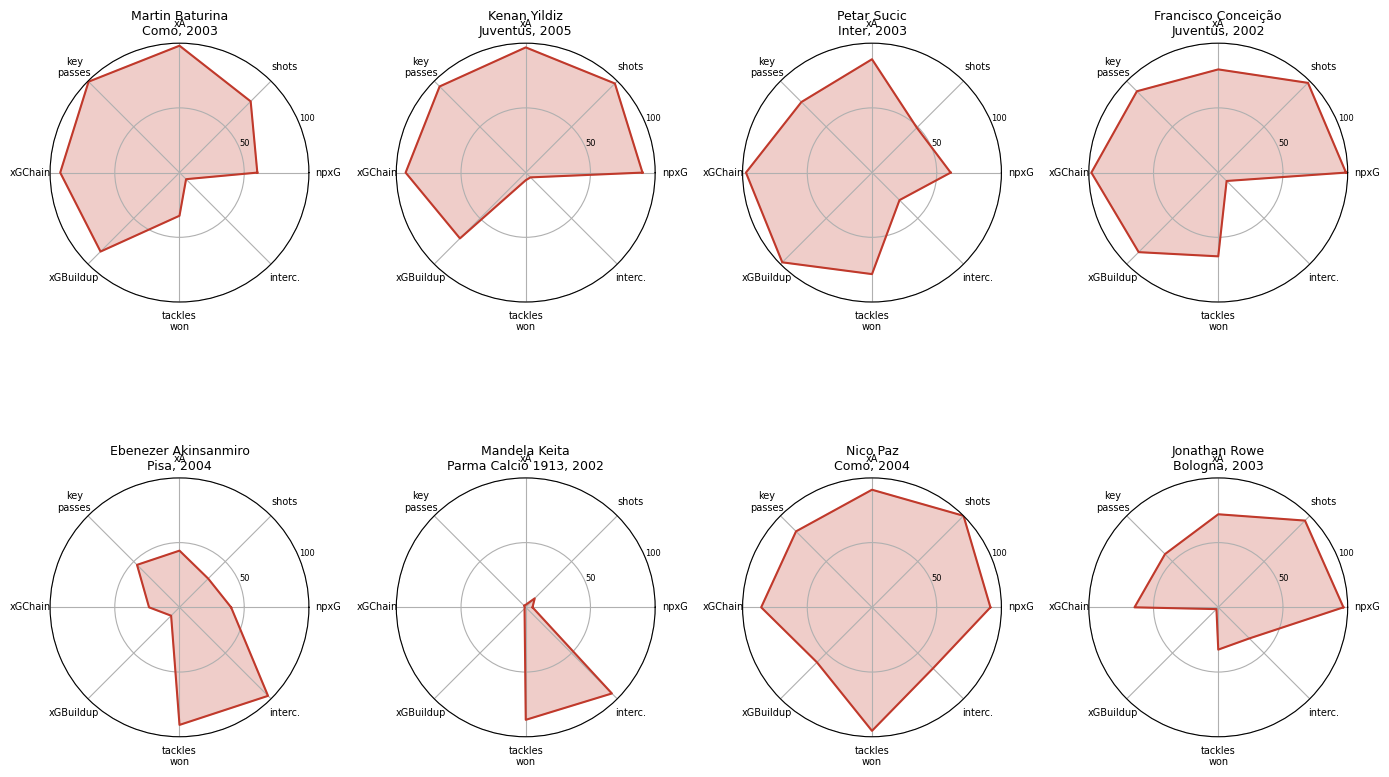


Martin Baturina | Como | born 2003 | 1579 min | profile: Creator (xA, key passes)
  strongest: KP90 99, xA90 98, xGChain90 92
  weakest:   TklW90 33, Int90 7
  similar:   Kevin De Bruyne (Napoli); Charles De Ketelaere (Atalanta); Matìas Soulè Malvano (Roma)

Kenan Yildiz | Juventus | born 2005 | 2877 min | profile: Creator (xA, key passes)
  strongest: shots90 97, xA90 96, KP90 94
  weakest:   TklW90 5, Int90 5
  similar:   Charles De Ketelaere (Atalanta); Matteo Politano (Napoli); Matìas Soulè Malvano (Roma)

Petar Sucic | Inter | born 2003 | 1763 min | profile: Builder (xGBuildup, xGChain)
  strongest: xGBuildup90 98, xGChain90 97, xA90 87
  weakest:   shots90 49, Int90 30
  similar:   Luis Henrique (Inter); Andrea Cambiaso (Juventus); Lucas Da Cunha (Como)

Francisco Conceição | Juventus | born 2002 | 2124 min | profile: Builder (xGBuildup, xGChain)
  strongest: npxG90 98, shots90 98, xGChain90 98
  weakest:   TklW90 64, Int90 9
  similar:   Jesús Rodriguez (Como); Matìas Soulè Mal

In [7]:
chosen = []
for name in PROFILES:
    pool = sa[(sa.Born >= 2002) & (sa.time >= 1400) & ~sa.player_name.isin([c[0] for c in chosen])]
    for i in pool.sort_values("score_" + name, ascending=False).head(2).index:
        chosen.append((sa.loc[i, "player_name"], name, i))

P = sa[["p_" + c for c in METRICS]].values
Pn = P / np.linalg.norm(P, axis=1, keepdims=True)
labels = ["npxG", "shots", "xA", "key\npasses", "xGChain", "xGBuildup", "tackles\nwon", "interc."]

fig = plt.figure(figsize=(14, 9))
for n, (pname, prof, i) in enumerate(chosen):
    ax = fig.add_subplot(2, 4, n + 1, polar=True)
    vals = list(P[i]) + [P[i][0]]
    ang = np.linspace(0, 2 * np.pi, len(METRICS), endpoint=False).tolist()
    ang += ang[:1]
    ax.plot(ang, vals, color="#c0392b"); ax.fill(ang, vals, color="#c0392b", alpha=0.25)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels, fontsize=7)
    ax.set_ylim(0, 100); ax.set_yticks([50, 100]); ax.set_yticklabels(["50", "100"], fontsize=6)
    ax.set_title(pname + "\n" + sa.loc[i, "team_title"] + ", " + str(int(sa.loc[i, "Born"])), fontsize=9)
plt.tight_layout(); plt.show()

for pname, prof, i in chosen:
    r = sa.loc[i]
    pc = pd.Series({c: r["p_" + c] for c in METRICS}).sort_values(ascending=False)
    sim = Pn @ Pn[i]
    order = np.argsort(-sim)
    comps = [sa.loc[k, "player_name"] + " (" + sa.loc[k, "team_title"] + ")" for k in order if k != i][:3]
    print("\n%s | %s | born %d | %d min | profile: %s" % (pname, r.team_title, r.Born, r.time, prof))
    print("  strongest:", ", ".join("%s %d" % (k, v) for k, v in pc.head(3).items()))
    print("  weakest:  ", ", ".join("%s %d" % (k, v) for k, v in pc.tail(2).items()))
    print("  similar:  ", "; ".join(comps))

## 6. Limits

- Metrics come from event data summaries (Understat) and a box-score file (FBref-based). There is no pressing, passing-under-pressure, carrying or off-ball data, and no video.
- Positions come from FBref and group wingers and attacking midfielders with central midfielders.
- 900-1,400 minutes is a small sample. The reliability table shows which metrics persist from one season to the next.
- Selection ignores age curves, injuries, contract and price. Market data are not included.
- Percentiles are relative to Serie A midfielders in one season only.